# Diesel or electric truck in India? Auditing a real-options model (v2)

**Version 1** (July 2026) valued buying an Ashok Leyland AVTR 1920 (diesel) against a Tata Prima E.28K
(electric) with a binomial lattice on the diesel price, and concluded: diesel is worth Rs 52.8 lakh
against Rs 37.1 lakh for the EV; diesel would need to reach Rs 117.31 a litre before the EV wins; and
at India's 7% diesel volatility the option to wait is worth exactly zero.

This notebook replicates the model, then asks whether its inputs describe one coherent decision, and
which assumptions actually decide the answer.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "charts"
R = {}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
INK, ACCENT, WARM, GREY = "#1F3A5F", "#2A9D8F", "#C8553D", "#8A8A8A"


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")


calib = json.loads((ROOT / "data" / "volatility_calibration.json").read_text())
# v1's inputs, exactly as in excel/build_model.py
V1 = dict(diesel_capex=2_550_000, kmpl=5.5, diesel_maint=4.0, ev_capex=4_000_000, charger=300_000, battery_kwh=453,
          range_km=175, power_tariff=7.5, ev_maint=2.0, km_per_year=90_000, freight=40.0, overhead=60_000, rate=0.12, life=8,
          diesel_price=calib["last_price"], sigma=calib["sigma_annual"], mu=calib["mu_annual"], horizon=5)


def annuity(r, n):
    return (1 - (1 + r) ** -n) / r


def npv_ev(p, kwh_per_km=None, tariff_growth=0.0):
    e = kwh_per_km if kwh_per_km is not None else p["battery_kwh"] / p["range_km"]
    flows = [p["km_per_year"] * (p["freight"] - e * p["power_tariff"] * (1 + tariff_growth) ** t - p["ev_maint"]) - p["overhead"]
             for t in range(p["life"])]
    return -p["ev_capex"] - p["charger"] + sum(f / (1 + p["rate"]) ** (t + 1) for t, f in enumerate(flows))


def npv_diesel(p, price, fuel_growth=0.0):
    flows = [p["km_per_year"] * (p["freight"] - price * (1 + fuel_growth) ** t / p["kmpl"] - p["diesel_maint"]) - p["overhead"]
             for t in range(p["life"])]
    return -p["diesel_capex"] + sum(f / (1 + p["rate"]) ** (t + 1) for t, f in enumerate(flows))


def lattice_option(p, ev_capex_decline=0.0, fuel_growth=0.0):
    """v1's decision tree: at each node choose buy EV, buy diesel, or wait a year (zero cash flow)."""
    u, d = np.exp(p["sigma"]), np.exp(-p["sigma"])
    q = (np.exp(p["mu"]) - d) / (u - d)
    H = p["horizon"]
    val = None
    for t in range(H, -1, -1):
        ev_t = npv_ev(dict(p, ev_capex=p["ev_capex"] * (1 - ev_capex_decline) ** t))
        prices = np.array([p["diesel_price"] * u ** (t - i) * d ** i for i in range(t + 1)])
        dz = np.array([npv_diesel(p, x, fuel_growth) for x in prices])
        now = np.maximum(ev_t, dz)
        if val is None:
            val = now
        else:
            wait = (q * val[:-1] + (1 - q) * val[1:]) / (1 + p["rate"])
            val = np.maximum(now, wait)
    commit = max(npv_ev(p), npv_diesel(p, p["diesel_price"], fuel_growth))
    return float(val[0]), float(val[0] - commit)


R["v1_npv_ev"], R["v1_npv_diesel"] = npv_ev(V1), npv_diesel(V1, V1["diesel_price"])
lo, hi = 50.0, 300.0
for _ in range(100):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if npv_diesel(V1, mid) > R["v1_npv_ev"] else (lo, mid)
R["v1_breakeven_price"] = mid
R["v1_flexible_value"], R["v1_option_value"] = lattice_option(V1)
print(f"EV Rs {R['v1_npv_ev'] / 1e5:.1f} lakh; diesel Rs {R['v1_npv_diesel'] / 1e5:.1f} lakh; breakeven Rs {mid:.2f}/litre; "
      f"option value Rs {R['v1_option_value']:,.0f}")

EV Rs 37.1 lakh; diesel Rs 52.8 lakh; breakeven Rs 117.31/litre; option value Rs 0


The Python replica reproduces every v1 number: Rs 37.1 lakh, Rs 52.8 lakh, Rs 117.31 a litre, and an option
value of zero.

## 1. Three inconsistencies inside the model

**(a) The EV cannot drive the assumed distance.** The model runs both trucks 90,000 km a year with
overnight depot charging and "no utilization derate". The E.28K's range is 150 to 220 km per charge.

In [2]:
for days in (365, 300):
    R[f"km_per_day_{days}"] = V1["km_per_year"] / days
R["one_charge_km_per_year_300d"] = V1["range_km"] * 300
print(f"90,000 km a year is {R['km_per_day_365']:.0f} km a day even driving all 365 days, {R['km_per_day_300']:.0f} km over 300 "
      f"working days; one 175 km charge a day over 300 days covers {R['one_charge_km_per_year_300d']:,} km")

90,000 km a year is 247 km a day even driving all 365 days, 300 km over 300 working days; one 175 km charge a day over 300 days covers 52,500 km


The EV case as modelled needs about 300 km a day over 300 working days, with one overnight charge good for
175. Either the truck charges again during the day (time and a charger the model does not cost) or it
covers about 52,500 km a year, not 90,000. The model's regional-duty framing and its distance assumption
cannot both hold.

**(b) The two trucks do different jobs.** The AVTR 1920 is an 18.5-tonne-GVW 4x2 haulage truck (10.5
tonnes payload); the Prima E.28K is a 28-tonne 6x4 tipper built for mining and construction. The model
credits both with the same Rs 40 a km of freight, and derives the EV's energy use as battery capacity
over spec range (453 / 175 = 2.59 kWh a km), a tipper's figure.

**(c) Diesel prices freeze the moment a truck is bought.** The lattice lets diesel drift up 5.1% a year
between decision dates, but each "buy diesel" value prices all eight years of fuel at the decision-day
price. Letting fuel follow the model's own drift inside each truck's life:

In [3]:
for g in (0.0, V1["mu"]):
    R[f"npv_diesel_fuel_growth_{g:.3f}"] = npv_diesel(V1, V1["diesel_price"], fuel_growth=g)
ev_per_km = V1["battery_kwh"] / V1["range_km"] * V1["power_tariff"] + V1["ev_maint"]
diesel_per_km = V1["diesel_price"] / V1["kmpl"] + V1["diesel_maint"]
R["ev_cost_per_km"], R["diesel_cost_per_km"] = ev_per_km, diesel_per_km
print(f"running cost per km: EV Rs {ev_per_km:.2f}, diesel Rs {diesel_per_km:.2f}")
print(f"diesel NPV with flat fuel Rs {R['npv_diesel_fuel_growth_0.000'] / 1e5:.1f} lakh; with the model's own 5.1% drift "
      f"Rs {R[f'npv_diesel_fuel_growth_{V1[chr(109) + chr(117)]:.3f}'] / 1e5:.1f} lakh (EV Rs {R['v1_npv_ev'] / 1e5:.1f} lakh)")

running cost per km: EV Rs 21.41, diesel Rs 21.82
diesel NPV with flat fuel Rs 52.8 lakh; with the model's own 5.1% drift Rs 39.7 lakh (EV Rs 37.1 lakh)


Two things stand out. Per kilometre, the trucks cost almost the same to run (Rs 21.41 against Rs 21.82),
because the tipper-derived energy use offsets electricity's lower price; the Rs 14.5 lakh difference in
purchase price therefore decides everything. And once diesel is allowed to rise at the model's own 5.1% a
year during each truck's life, the diesel truck's value falls from Rs 52.8 to Rs 39.7 lakh: **the 42% gap
becomes 7%** (Rs 2.6 lakh), within the error of almost every input.

## 2. Is India's diesel really a 7%-volatility asset?

The volatility comes from 11 annual averages, 2015 to 2026, described as the post-deregulation window.
Three problems:

- **Averaging hides volatility.** Returns between annual averages of a random walk have about two-thirds
  of its variance, so a 7% figure from averages corresponds to roughly 8.6% at a point in time.
- **The window is not deregulated.** Retail diesel prices were frozen nationally from April 2022 (apart
  from a Rs 2 cut in March 2024) until 15 May 2026, then rose 8.6% in ten days as the Hormuz shock broke the
  freeze (The Tribune, 23 April 2026; Bloomberg, 15 May 2026). Low measured volatility partly reflects a
  policy that absorbed price risk on state retailers' balance sheets, until it did not.
- **The series is inconsistent with that freeze.** It rises from 91 (2022) to 101.23 (2025), about 11%,
  while pump prices were frozen; its source page no longer exists, so its city or basis cannot be checked.

In [4]:
px = pd.read_csv(ROOT / "data" / "diesel_price_india.csv")
post = px[px["year"] >= 2015]
r = np.diff(np.log(post["avg_diesel_price_inr_per_litre"]))
n = len(r)
R["sigma_annual_avg"] = float(r.std(ddof=1))
R["sigma_point_in_time_approx"] = float(r.std(ddof=1) / np.sqrt(2 / 3))
from scipy.stats import chi2  # noqa: E402
R["sigma_ci"] = [float(np.sqrt((n - 1) * r.var(ddof=1) / chi2.ppf(0.975, n - 1))), float(np.sqrt((n - 1) * r.var(ddof=1) / chi2.ppf(0.025, n - 1)))]
R["series_rise_2022_2025"] = float(px.set_index("year").loc[2025].iloc[0] / px.set_index("year").loc[2022].iloc[0] - 1)
print(f"{n} annual returns: sigma {R['sigma_annual_avg']:.3f} (95% CI {R['sigma_ci'][0]:.3f} to {R['sigma_ci'][1]:.3f}); "
      f"point-in-time equivalent about {R['sigma_point_in_time_approx']:.3f}")
print(f"series change 2022 to 2025, a period of frozen pump prices: {R['series_rise_2022_2025']:+.1%}")
opt = []
for s in (0.07, 0.10, 0.20, 0.30, 0.43):
    opt.append({"sigma": s, "option_value_lakh": lattice_option(dict(V1, sigma=s))[1] / 1e5})
opt = pd.DataFrame(opt)
R["option_value_by_sigma"] = opt.round(3).to_dict(orient="records")
print(opt.round(2).to_string(index=False))

11 annual returns: sigma 0.070 (95% CI 0.049 to 0.123); point-in-time equivalent about 0.086
series change 2022 to 2025, a period of frozen pump prices: +11.2%
 sigma  option_value_lakh
  0.07               0.00
  0.10               0.00
  0.20               0.00
  0.30               0.00
  0.43               3.73


Eleven annual returns pin volatility down only loosely (95% interval 4.9% to 12.3%), and the
point-in-time figure is nearer 8.6%. More importantly, part of that window is a price freeze, and the
series itself rises 11.2% during it. The option to wait stays at zero until volatility reaches crude's
level (Rs 3.7 lakh at 43%), as v1 found; but v1's reading, that India's diesel is a stable, low-risk input,
was a statement about a subsidy policy, and that policy broke in May 2026.

## 3. Which assumptions decide the answer?

The NPV gap (EV minus diesel) re-computed with one input moved at a time across a plausible range,
others at v1's values. Ranges: the model's own notes where it gives them (EV price Rs 35 to 45 lakh,
range 150 to 200 km), otherwise stated assumptions. Energy use spans a heavy electric truck on a road
duty cycle (about 1.3 kWh a km, an assumption) to v1's tipper-derived 2.59 and above.

v1 gap -15.7 lakh
                      input       low       high  gap_at_low  gap_at_high
              Discount rate       0.1       0.15      -15.56       -15.87
       Annual distance (km)   50000.0   90000.00      -16.50       -15.69
     EV maintenance (Rs/km)       1.5       3.00      -13.46       -20.17
         EV price (Rs lakh) 3500000.0 4500000.00      -10.69       -20.69
    Diesel price (Rs/litre)      88.0     110.00      -23.82        -5.94
  Diesel mileage (km/litre)       5.0       6.50       -7.73       -27.95
     EV energy use (kWh/km)       1.3       3.00       27.51       -29.49
Electricity tariff (Rs/kWh)       5.0      12.00       13.24       -67.77


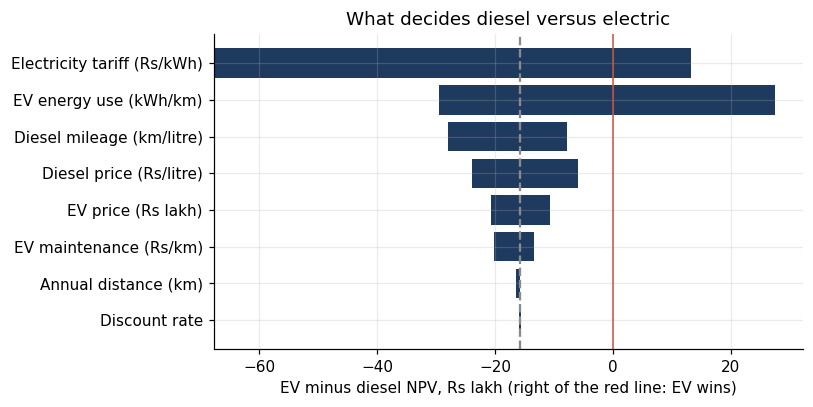

In [5]:
RANGES = {"EV energy use (kWh/km)": ("kwh", 1.3, 3.0), "Electricity tariff (Rs/kWh)": ("power_tariff", 5.0, 12.0),
          "EV price (Rs lakh)": ("ev_capex", 3_500_000, 4_500_000), "Annual distance (km)": ("km_per_year", 50_000, 90_000),
          "Diesel price (Rs/litre)": ("diesel_price", 88.0, 110.0), "Diesel mileage (km/litre)": ("kmpl", 5.0, 6.5),
          "Discount rate": ("rate", 0.10, 0.15), "EV maintenance (Rs/km)": ("ev_maint", 1.5, 3.0)}


def gap(p, kwh=None, fuel_growth=0.0):
    return npv_ev(p, kwh) - npv_diesel(p, p["diesel_price"], fuel_growth)


base_gap = gap(V1)
rows = []
for label, (key, a, b) in RANGES.items():
    vals = []
    for v in (a, b):
        vals.append(gap(V1, kwh=v) if key == "kwh" else gap(dict(V1, **{key: v})))
    rows.append({"input": label, "low": a, "high": b, "gap_at_low": vals[0], "gap_at_high": vals[1], "swing": abs(vals[1] - vals[0])})
tor = pd.DataFrame(rows).sort_values("swing")
R["base_gap"] = base_gap
R["tornado"] = tor.round(0).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, r_ in enumerate(tor.itertuples()):
    lo_, hi_ = sorted([r_.gap_at_low, r_.gap_at_high])
    ax.barh(i, (hi_ - lo_) / 1e5, left=lo_ / 1e5, color=INK)
ax.set_yticks(range(len(tor)), tor["input"])
ax.axvline(0, color=WARM, lw=1)
ax.axvline(base_gap / 1e5, color=GREY, ls="--")
ax.set(xlabel="EV minus diesel NPV, Rs lakh (right of the red line: EV wins)", title="What decides diesel versus electric")
save(fig, "03_tornado.png")
print(f"v1 gap {base_gap / 1e5:.1f} lakh")
print(tor.assign(gap_at_low=lambda x: x.gap_at_low / 1e5, gap_at_high=lambda x: x.gap_at_high / 1e5)[["input", "low", "high", "gap_at_low", "gap_at_high"]].round(2).to_string(index=False))

**The answer turns on the electricity tariff and the EV's energy use, not on diesel.** Across Rs 5 to 12
a kWh the gap swings from EV ahead by Rs 13 lakh to diesel ahead by Rs 68 lakh; across 1.3 to 3.0 kWh a km,
from EV ahead by Rs 28 lakh to diesel ahead by Rs 29 lakh. Diesel's price and mileage matter less; the
discount rate hardly at all.

### All uncertainties at once

A Monte Carlo draws every input uniformly from its range (and lets diesel follow the model's drift
within each truck's life), 20,000 times. Which inputs move the answer most is read from rank
correlations with the NPV gap.

EV better in 44.5% of draws; median gap Rs -3.0 lakh
Electricity tariff (Rs/kWh)   -0.653
EV energy use (kWh/km)        -0.625
Diesel mileage (km/litre)     -0.219
Diesel price (Rs/litre)        0.173
EV price (Rs lakh)            -0.123
Annual distance (km)           0.113
EV maintenance (Rs/km)        -0.069
Discount rate                 -0.036


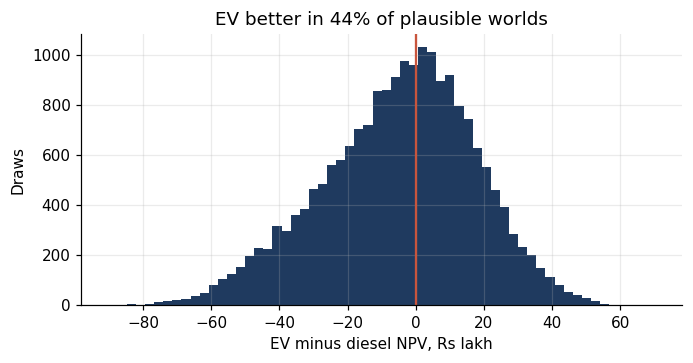

In [6]:
rng = np.random.default_rng(20261007)
N = 20000
draws = {label: rng.uniform(a, b, N) for label, (_, a, b) in RANGES.items()}
gaps = np.empty(N)
for i in range(N):
    p = dict(V1)
    for label, (key, a, b) in RANGES.items():
        if key != "kwh":
            p[key] = draws[label][i]
    gaps[i] = gap(p, kwh=draws["EV energy use (kWh/km)"][i], fuel_growth=V1["mu"])
R["mc_p_ev_better"] = float((gaps > 0).mean())
R["mc_median_gap"] = float(np.median(gaps))
infl = {label: float(spearmanr(draws[label], gaps)[0]) for label in RANGES}
R["mc_rank_corr"] = infl
print(f"EV better in {R['mc_p_ev_better']:.1%} of draws; median gap Rs {np.median(gaps) / 1e5:.1f} lakh")
print(pd.Series(infl).sort_values(key=abs, ascending=False).round(3).to_string())
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(gaps / 1e5, bins=60, color=INK)
ax.axvline(0, color=WARM)
ax.set(xlabel="EV minus diesel NPV, Rs lakh", ylabel="Draws", title=f"EV better in {R['mc_p_ev_better']:.0%} of plausible worlds")
save(fig, "04_monte_carlo.png")

With every input uncertain at once, the EV comes out ahead in 44.5% of draws and the median difference is
Rs 3 lakh in diesel's favour: **a coin toss, not a 42% win**. The tariff and the energy use explain most of
the variation (rank correlations -0.65 and -0.63). An operator should pin those two down, with a tariff
quote for the depot and a measured kWh per km on the route, before any option model.

## 4. The option worth valuing

v1 valued the option to wait for *diesel prices* to reveal themselves and found it worthless. The more
plausible reason to wait is that electric trucks get cheaper. Holding everything else at v1's values,
but letting diesel follow the model's own drift within each truck's life (Section 1c), the value of
keeping the decision open when EV prices fall a given percentage a year (an assumption):

In [7]:
dec = []
for g in (0.0, 0.05, 0.10, 0.15):
    dec.append({"ev_price_decline_per_year": g, "option_value_lakh": lattice_option(V1, ev_capex_decline=g, fuel_growth=V1["mu"])[1] / 1e5})
dec = pd.DataFrame(dec)
R["option_value_by_ev_decline"] = dec.round(3).to_dict(orient="records")
print(dec.round(2).to_string(index=False))

 ev_price_decline_per_year  option_value_lakh
                      0.00                0.0
                      0.05                0.0
                      0.10                0.0
                      0.15                0.0


Still zero, and it would stay zero for any plausible decline. In v1's tree, "wait" means running no truck
for a year, giving up about Rs 16 lakh of operating cash flow; no saving on a cheaper EV or information
about diesel can repay that. The real option a fleet holds is different: **buy what wins today and switch
technology at the next replacement**, or lease while EV costs fall. Modelling that needs a replacement
cycle, which v1's single-purchase tree does not have.

## 5. Conclusions and limits

| v1 | v2 |
|---|---|
| Diesel worth Rs 52.8 lakh vs EV Rs 37.1 lakh (42% gap) | Replicated; but fuel is held at today's price for eight years. With the model's own 5.1% drift: Rs 39.7 vs Rs 37.1 lakh (7%) |
| Inputs real and sourced | The two trucks are different classes (18.5-tonne haulage vs 28-tonne mining tipper); the EV cannot cover 90,000 km a year on one charge a day |
| Diesel volatility 7% (post-deregulation) | Loosely estimated (4.9% to 12.3%); the window includes a four-year price freeze that broke in May 2026; the series rises 11% during the freeze |
| Value of waiting is zero | True, but because waiting means idling a year's business; the meaningful option is switching at replacement |
| Diesel by a wide margin | A coin toss (EV ahead in 44.5% of draws), decided by the electricity tariff and the EV's energy use |

**Limits.** Input ranges are assumptions stated in the notebook; the EV energy figure for a road duty
cycle (1.3 kWh a km) is an assumption, not a measurement; battery degradation, resale and financing are
outside both versions.

In [8]:
(ROOT / "results_v2.json").write_text(json.dumps(R, indent=1, default=float))
print(json.dumps({k: v for k, v in R.items() if not isinstance(v, (dict, list))}, indent=1, default=float))

{
 "v1_npv_ev": 3711383.6182629718,
 "v1_npv_diesel": 5280806.686998283,
 "v1_breakeven_price": 117.30679196468009,
 "v1_flexible_value": 5280806.686998283,
 "v1_option_value": 0.0,
 "km_per_day_365": 246.57534246575344,
 "km_per_day_300": 300.0,
 "one_charge_km_per_year_300d": 52500,
 "npv_diesel_fuel_growth_0.000": 5280806.686998283,
 "npv_diesel_fuel_growth_0.051": 3973031.934622406,
 "ev_cost_per_km": 21.414285714285715,
 "diesel_cost_per_km": 21.818181818181817,
 "sigma_annual_avg": 0.06991043623821933,
 "sigma_point_in_time_approx": 0.08562244823950782,
 "series_rise_2022_2025": 0.11241758241758237,
 "base_gap": -1569423.0687353108,
 "mc_p_ev_better": 0.44475,
 "mc_median_gap": -302642.37513731606
}
